In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../..")

from src.utils.utils_xarray import sel_extent
sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 34}

In [5]:
climate_scenario = "rcp85"

ds_runoff_rcp85 = sel_extent(
    xr.open_zarr(
        path_data_temporary
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "regridded"
        / "day"
        / "mrro.zarr"
    ),
    extent,
).sel(time=slice("2031", "2050"))

ds_runoff_bc_rcp85 = sel_extent(
    xr.open_zarr(
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_scenario}"
        / "bias_corrected"
        / "day"
        / "mrro.zarr"
    ),
    extent,
).sel(time=slice("2031", "2050"))

In [6]:
ds_runoff_bc_regridded_rcp85 = sel_extent(
    xr.open_dataset(
        "/net/exo/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/temp/mrro/blocks/mrro_masked_regridded_2031_2050.nc"
    ),
    extent,
)

In [7]:
path_routed_rcp85 = Path("/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-85/")
paths_routed_rcp85_zarr = sorted(path_routed_rcp85.glob("*/*.zarr"))
path_routed_rcp26 = Path("/net/argon/landclim2/pseubert/out_rcm/hist/CNRM-26/")
paths_routed_rcp26_zarr = sorted(path_routed_rcp26.glob("*/*.zarr"))

# Filter paths for years 2031-2050
paths_2031_2050 = [p for p in paths_routed_rcp85_zarr if any(str(y) in str(p) for y in range(2031, 2051))]
# Load datasets
datasets = [xr.open_zarr(p) for p in paths_2031_2050]
# Combine by coordinates
ds_runoff_bc_routed_rcp85 = sel_extent(xr.combine_by_coords(datasets, combine_attrs="drop_conflicts"), extent)

In [8]:
ds_runoff_cerra = xr.open_dataset("/landclim/yhaddad/clim2energy-ch/cerra_processed/ro/ro_day_cerra-land_2020.nc")
ds_runoff_cerra

<xarray.Dataset> Size: 2GB
Dimensions:            (time: 366, x: 1069, y: 1069, lev: 1)
Coordinates:
  * time               (time) datetime64[ns] 3kB 2020-01-01 ... 2020-12-31
  * x                  (x) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * y                  (y) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * lev                (lev) float64 8B 0.0
Data variables:
    Lambert_Conformal  int32 4B ...
    ro                 (time, y, x, lev) float32 2GB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Sat Mar 08 09:05:41 2025: cdo setgrid,/net/exo/landclim/yha...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...

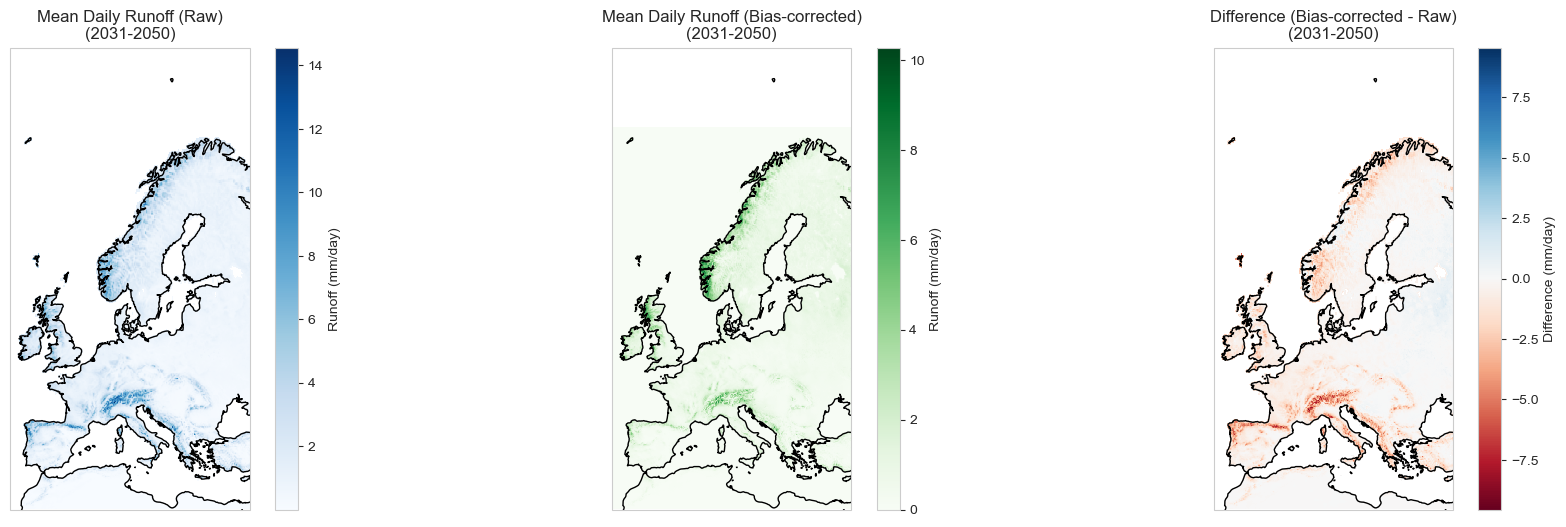

In [10]:
# Compute mean runoff per grid cell over time
mean_raw = ds_runoff_rcp85['mrro'].mean(dim='time') * 86400
mean_bc = ds_runoff_bc_rcp85['mrro'].mean(dim='time')

# Compute the difference
mean_diff = mean_bc - mean_raw

fig, axes = plt.subplots(1, 3, figsize=(22, 6), subplot_kw={'projection': ccrs.Mercator()})

# Plot mean_raw
mean_raw.plot(
    ax=axes[0],
    cmap='Blues',
    cbar_kwargs={'label': 'Runoff (mm/day)'},
    transform=ccrs.PlateCarree()
)
axes[0].set_title('Mean Daily Runoff (Raw)\n(2031-2050)')
axes[0].coastlines()
axes[0].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

# Plot mean_bc
mean_bc.plot(
    ax=axes[1],
    cmap='Greens',
    cbar_kwargs={'label': 'Runoff (mm/day)'},
    transform=ccrs.PlateCarree()
)
axes[1].set_title('Mean Daily Runoff (Bias-corrected)\n(2031-2050)')
axes[1].coastlines()
axes[1].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

# Plot mean_diff
vmax = np.nanmax(np.abs(mean_diff))
mean_diff.plot(
    ax=axes[2],
    cmap='RdBu',
    vmin=-vmax,
    vmax=vmax,
    cbar_kwargs={'label': 'Difference (mm/day)'},
    transform=ccrs.PlateCarree()
)
axes[2].set_title('Difference (Bias-corrected - Raw)\n(2031-2050)')
axes[2].coastlines()
axes[2].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

plt.show()

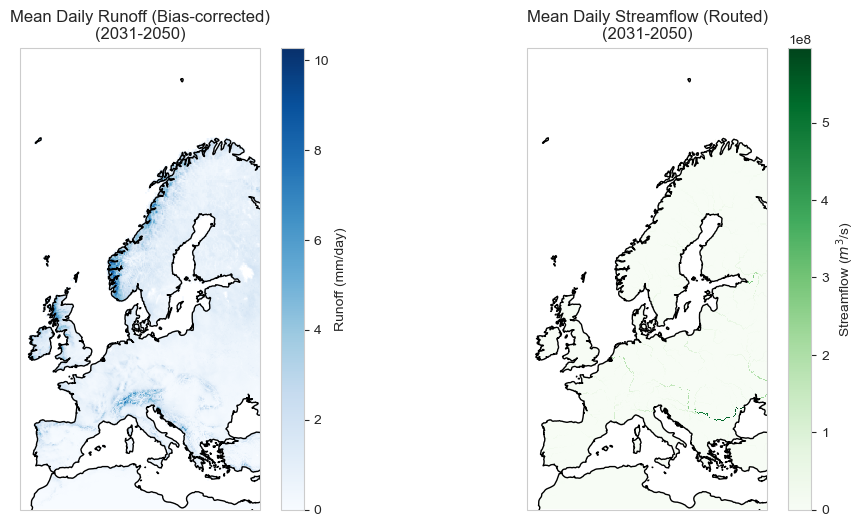

In [11]:
# Compute mean runoff per grid cell over time
mean_bc_regridded = ds_runoff_bc_regridded_rcp85['mrro'].mean(dim='time')
mean_routed = ds_runoff_bc_routed_rcp85['Qrouted'].mean(dim='time')

# # Compute the difference
# mean_diff_bc_routed = mean_routed - mean_bc_regridded


fig, axes = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': ccrs.Mercator()})

# Plot mean_raw
mean_bc_regridded.plot(
    ax=axes[0],
    cmap='Blues',
    cbar_kwargs={'label': 'Runoff (mm/day)'},
    transform=ccrs.PlateCarree()
)
axes[0].set_title('Mean Daily Runoff (Bias-corrected)\n(2031-2050)')
axes[0].coastlines()
axes[0].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

# Plot mean_bc
mean_routed.plot(
    ax=axes[1],
    cmap='Greens',
    cbar_kwargs={'label': r'Streamflow ($m^3$/s)'},
    transform=ccrs.PlateCarree()
)
axes[1].set_title('Mean Daily Streamflow (Routed)\n(2031-2050)')
axes[1].coastlines()
axes[1].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

# # Plot mean_diff
# vmax = np.nanmax(np.abs(mean_diff))
# mean_diff.plot(
#     ax=axes[2],
#     cmap='RdBu',
#     vmin=-vmax,
#     vmax=vmax,
#     cbar_kwargs={'label': 'Difference (mm/day)'},
#     transform=ccrs.PlateCarree()
# )
# axes[2].set_title('Difference (Bias-corrected - Raw)\n(2031-2050)')
# axes[2].coastlines()
# axes[2].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

plt.show()

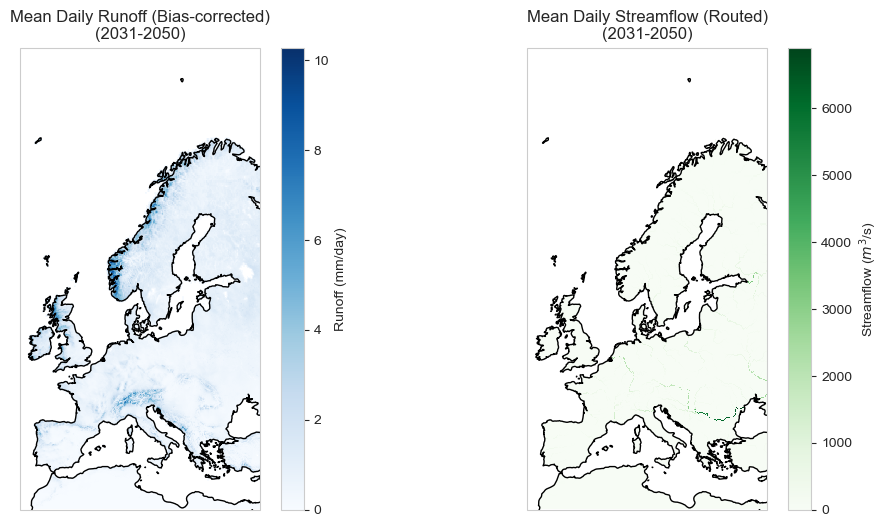

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), subplot_kw={'projection': ccrs.Mercator()})

# Plot mean_raw
mean_bc_regridded.plot(
    ax=axes[0],
    cmap='Blues',
    cbar_kwargs={'label': 'Runoff (mm/day)'},
    transform=ccrs.PlateCarree()
)
axes[0].set_title('Mean Daily Runoff (Bias-corrected)\n(2031-2050)')
axes[0].coastlines()
axes[0].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])

# Plot mean_bc
(mean_routed / 86400).plot(
    ax=axes[1],
    cmap='Greens',
    cbar_kwargs={'label': r'Streamflow ($m^3$/s)'},
    transform=ccrs.PlateCarree(),
)
axes[1].set_title('Mean Daily Streamflow (Routed)\n(2031-2050)')
axes[1].coastlines()
axes[1].set_extent([extent['lon_min'], extent['lon_max'], extent['lat_min'], extent['lat_max']])